In [181]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

data = pd.read_csv('ecom_data.csv', index_col = 0)

## Data Preprocessing

#### Missing Values

In [182]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 541909 entries, 536365 to 581587
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   StockCode    541909 non-null  object 
 1   Description  540455 non-null  object 
 2   Quantity     541909 non-null  int64  
 3   InvoiceDate  541909 non-null  object 
 4   UnitPrice    541909 non-null  float64
 5   CustomerID   406829 non-null  float64
 6   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [183]:
missing_percentage = data.isnull().mean() * 100
print(missing_percentage)

StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64


In [184]:
data = data.dropna(subset=['Description', 'CustomerID'])

*Rows with missing values in 'Description' and 'CustomerID' were removed*

#### Extreme Negative Quantity Investigation

In [185]:
data.describe()

,Quantity,UnitPrice,CustomerID
count,406829.000000,406829.000000,406829.000000
mean,12.061303,3.460471,15287.690570
std,248.693370,69.315162,1713.600303
min,-80995.000000,0.000000,12346.000000
25%,2.000000,1.250000,13953.000000
50%,5.000000,1.950000,15152.000000
75%,12.000000,3.750000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [186]:
data.columns

Index(['StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice',
       'CustomerID', 'Country'],
      dtype='object')

In [187]:
data.index[:10]

Index(['536365', '536365', '536365', '536365', '536365', '536365', '536365',
       '536366', '536366', '536367'],
      dtype='object', name='InvoiceNo')

*Extreme minimum negative values of Quantity were suspicious (may be potential outliers), thus further investigation is needed*

In [188]:
neg_qty = data[data['Quantity'] < 0].sort_values('Quantity').head()

print(neg_qty.shape)

(5, 7)


In [189]:
neg_qty

,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
InvoiceNo,,,,,,,
C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,12/9/2011 9:27,2.08,16446.0,United Kingdom
C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1/18/2011 10:17,1.04,12346.0,United Kingdom
C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,12/2/2010 14:23,0.03,15838.0,United Kingdom
C550456,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,-3114,4/18/2011 13:08,2.10,15749.0,United Kingdom
C550456,21175,GIN + TONIC DIET METAL SIGN,-2000,4/18/2011 13:08,1.85,15749.0,United Kingdom


*We looked at the negative value of qunatity, and found they all belonged to invoices starting with letter 'C' (likely refers to 'cancellation')*

In [190]:
data[data['StockCode'] == '23843'].sort_values('Quantity', ascending=False).head()

,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
InvoiceNo,,,,,,,
581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,12/9/2011 9:15,2.08,16446.0,United Kingdom
C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,12/9/2011 9:27,2.08,16446.0,United Kingdom


*We matched the negative transaction one by one starting from StockCode=23843 to earlier positive transactions. The quantity, customers, products, and prices matched exactly. Therefore, this extreme negative quantity is cancellations, not error*

In [191]:
data[data['StockCode'] == '23166'].sort_values('Quantity', ascending=True).head()

,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
InvoiceNo,,,,,,,
C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1/18/2011 10:17,1.04,12346.0,United Kingdom
C557508,23166,MEDIUM CERAMIC TOP STORAGE JAR,-240,6/20/2011 16:13,1.04,16684.0,United Kingdom
C570867,23166,MEDIUM CERAMIC TOP STORAGE JAR,-12,10/12/2011 16:17,1.25,12607.0,USA
C562375,23166,MEDIUM CERAMIC TOP STORAGE JAR,-12,8/4/2011 14:46,1.25,14911.0,EIRE
C554527,23166,MEDIUM CERAMIC TOP STORAGE JAR,-9,5/24/2011 17:25,1.04,15251.0,United Kingdom


*For StockCode=23166, we agained sucessfully matched it with an earlier positive transaction, therefore, confirmed the negative value of quantity (-74215) is a cancellation, not error*

#### Duplicate Records

In [192]:
dup_count = data.duplicated().sum()
print(dup_count)

5265


In [193]:
data[data.duplicated(keep=False)].head()

,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
InvoiceNo,,,,,,,
536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom


In [194]:
data = data.drop_duplicates()

In [195]:
dup_count = data.duplicated().sum()
print(dup_count)

0


#### Remove Cancellations and Non-Inventory Records 
*For customer purchase analysis and ABC analysis, usually we want a complete sales excluding returns/cancellations, and non-inventory records*

In [196]:
data.groupby('InvoiceNo')['Description'].first().sort_index()

InvoiceNo
536365     WHITE HANGING HEART T-LIGHT HOLDER
536366                 HAND WARMER UNION JACK
536367          ASSORTED COLOUR BIRD ORNAMENT
536368               JAM MAKING SET WITH JARS
536369               BATH BUILDING BLOCK WORD
                          ...                
C581484           PAPER CRAFT , LITTLE BIRDIE
C581490       VICTORIAN GLASS HANGING T-LIGHT
C581499                                Manual
C581568            VICTORIAN SEWING BOX LARGE
C581569      HANGING HEART JAR T-LIGHT HOLDER
Name: Description, Length: 22188, dtype: object

In [197]:
data = data[~data.index.astype(str).str.startswith('C')]

In [198]:
data.groupby('StockCode')['Description'].first().sort_index()

StockCode
10002     INFLATABLE POLITICAL GLOBE 
10080        GROOVY CACTUS INFLATABLE
10120                    DOGGY RUBBER
10123C          HEARTS WRAPPING TAPE 
10124A    SPOTS ON RED BOOKCOVER TAPE
                     ...             
C2                           CARRIAGE
DOT                    DOTCOM POSTAGE
M                              Manual
PADS       PADS TO MATCH ALL CUSHIONS
POST                          POSTAGE
Name: Description, Length: 3665, dtype: object

In [199]:
# Non-Inventory Records
non_inventory = ['DOT',
'POST',
'BANK CHARGES',
'M',
'm',
'CRUK',
'C2'
]

data = data[~data['StockCode'].isin(non_inventory)]

In [200]:
# Not physical inventory item

data = data[~data['StockCode'].str.startswith('gift', na=False)]

In [201]:
data[data['StockCode'].str.startswith('gift', na=False)]

,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
InvoiceNo,,,,,,,


*Several non-product stock codes were identified during ABC analysis, including POST (POSTAGE), DOT (DOTCOM POSTAGE), C2 (CARRIAGE), BANK CHARGES, M (Manual), CRUK, and gift voucher codes. As these entries do not represent physical products that can be stocked or replenished, they were removed to ensure the ABC analysis and subsequent inventory optimisation focused solely on actual inventory items.*

In [202]:
data.groupby('StockCode')['Description'].first().sort_index()

StockCode
10002     INFLATABLE POLITICAL GLOBE 
10080        GROOVY CACTUS INFLATABLE
10120                    DOGGY RUBBER
10123C          HEARTS WRAPPING TAPE 
10124A    SPOTS ON RED BOOKCOVER TAPE
                     ...             
90214V      LETTER "V" BLING KEY RING
90214W      LETTER "W" BLING KEY RING
90214Y      LETTER "Y" BLING KEY RING
90214Z      LETTER "Z" BLING KEY RING
PADS       PADS TO MATCH ALL CUSHIONS
Name: Description, Length: 3660, dtype: object

#### Remove Non-Positive Prices

In [203]:
data[data['UnitPrice'] <= 0]

,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
InvoiceNo,,,,,,,
537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,12/5/2010 14:02,0.0,12647.0,Germany
539263,22580,ADVENT CALENDAR GINGHAM SACK,4,12/16/2010 14:36,0.0,16560.0,United Kingdom
539722,22423,REGENCY CAKESTAND 3 TIER,10,12/21/2010 13:45,0.0,14911.0,EIRE
540372,22090,PAPER BUNTING RETROSPOT,24,1/6/2011 16:41,0.0,13081.0,United Kingdom
540372,22553,PLASTERS IN TIN SKULLS,24,1/6/2011 16:41,0.0,13081.0,United Kingdom
541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,1/13/2011 15:10,0.0,15107.0,United Kingdom
543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2/10/2011 13:08,0.0,17560.0,United Kingdom
547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,3/23/2011 10:25,0.0,13239.0,United Kingdom
548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,3/30/2011 12:45,0.0,13113.0,United Kingdom


In [204]:
data = data[data['UnitPrice'] > 0]

*Records with non-positive unit price were removed as they were not actual product sales*

#### Covert Date

In [205]:
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])

In [206]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 391114 entries, 536365 to 581587
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   StockCode    391114 non-null  object        
 1   Description  391114 non-null  object        
 2   Quantity     391114 non-null  int64         
 3   InvoiceDate  391114 non-null  datetime64[ns]
 4   UnitPrice    391114 non-null  float64       
 5   CustomerID   391114 non-null  float64       
 6   Country      391114 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(3)
memory usage: 23.9+ MB


## Revenue Analysis

In [207]:
data['Revenue'] = data['Quantity'] * data['UnitPrice']

In [208]:
data['Revenue'].describe()

count    391114.000000
mean         22.335682
std         310.943339
min           0.001000
25%           4.950000
50%          11.900000
75%          19.800000
max      168469.600000
Name: Revenue, dtype: float64

### Top Revenue by countries 

In [209]:
country_rev = data.groupby('Country')['Revenue'].sum().sort_values(ascending=False)

country_rev.head(10)

Country
United Kingdom    7241425.483
Netherlands        283889.340
EIRE               257013.120
Germany            205381.150
France             183801.940
Australia          138103.810
Spain               55706.560
Switzerland         52441.950
Japan               37416.370
Belgium             36927.340
Name: Revenue, dtype: float64

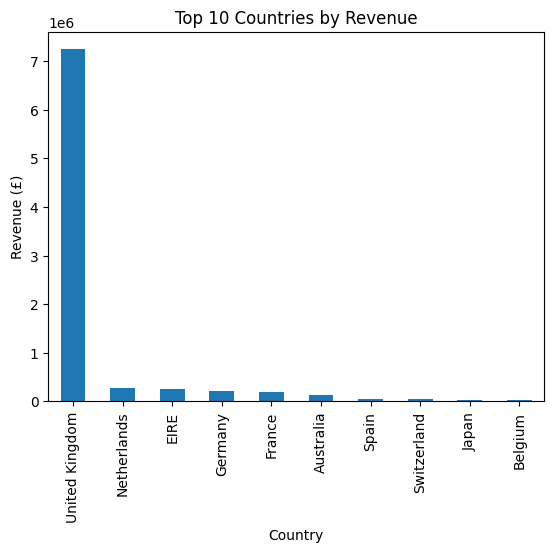

In [210]:
country_rev.head(10).plot(kind='bar')

plt.title('Top 10 Countries by Revenue')
plt.ylabel('Revenue (£)')
plt.show()

*The United Kingdom generated the highest revenue by a substantial margin, indicating that it is the primary market.*

### Top Products by Revenue

In [211]:
data.groupby('Description')['Revenue'].sum().sort_values(ascending = False).head(10)

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
RABBIT NIGHT LIGHT                     51251.24
CHILLI LIGHTS                          46265.11
PAPER CHAIN KIT 50'S CHRISTMAS         42584.13
Name: Revenue, dtype: float64

*The top 3 products by revenue were Paper Craft, Little Birdie (£168,469.60), Regency Cakestand 3 Tier (£142,264.75), and White Hanging Heart T-light Holder (£100,392.100), each generating over £100,000 in sales*

### Monthly Revenue Trend

In [212]:
monthly_revenue = data.groupby(data['InvoiceDate'].dt.to_period('M'))['Revenue'].sum()

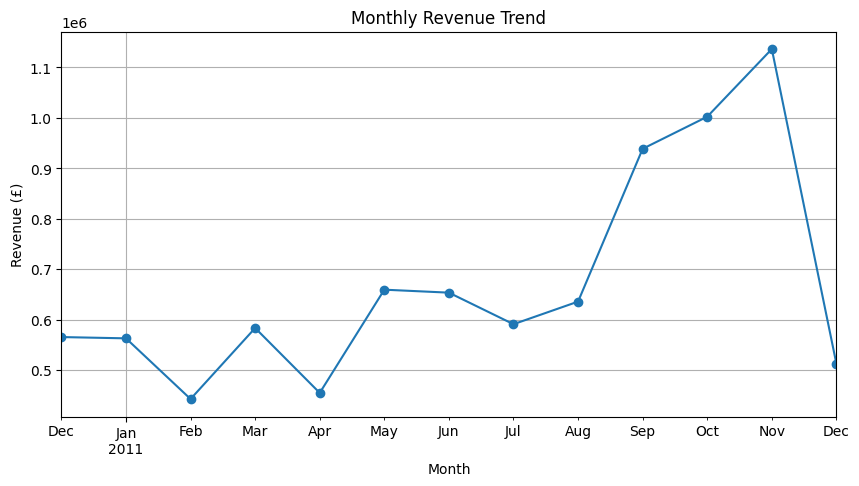

In [213]:
plt.figure(figsize=(10, 5))
monthly_revenue.plot(marker='o') 

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.grid(True)

plt.show()

- Revenue was relatively stable between Dec 2010 and Aug 2011
- Revenue then increased sharply from Sep to Nov 2011
- Nov 2011 recorded the highest revenue 
- The final drop in December 2011 is likely because the dataset only contains part of Dec not the full month

*Monthly revenue remained relatively stable during most of the year before incrasing significantky from September onwards. Revenue peaked in November 2011 at approximately £1.15m, indicating strong seasonal demand. The sharp decine in December 2011 is likely due to the dateaset contain only a partial month of transactions.*

## ABC Analysis

In [214]:
# Revenue by SKU
abc = data.groupby('StockCode')['Revenue'].sum().sort_values(ascending = False)

abc.head()

StockCode
23843     168469.60
22423     142264.75
85123A    100547.45
85099B     85040.54
23166      81416.73
Name: Revenue, dtype: float64

In [215]:
# Convert to DataFrame

abc = abc.reset_index()
abc.columns = ['StockCode', 'Revenue']

In [216]:
abc.head()

,StockCode,Revenue
0,23843,168469.60
1,22423,142264.75
2,85123A,100547.45
3,85099B,85040.54
4,23166,81416.73


In [217]:
# Revenue contribution % 
# How much one SKU alone contributes to total revenue

abc['Revenue_%'] = abc['Revenue'] /abc['Revenue'].sum() * 100

In [218]:
# Cumulative revenue %
# Adds up the contribution perceages from top to bottom

abc['Cumulative_%'] = abc['Revenue_%'].cumsum()

In [219]:
abc['Revenue'].sum()

np.float64(8735797.803)

In [220]:
abc.head(10)

# Top SKU earned about £168k, entire business earned about £8.7m 
# So, we can see that the total revenue is not heavily dependent on a single product. Instead, the total revenue is distributed across many SKUs

,StockCode,Revenue,Revenue_%,Cumulative_%
0,23843,168469.60,1.928497,1.928497
1,22423,142264.75,1.628526,3.557023
2,85123A,100547.45,1.150982,4.708005
3,85099B,85040.54,0.973472,5.681477
4,23166,81416.73,0.931990,6.613467
5,47566,68785.23,0.787395,7.400862
6,84879,56413.03,0.645768,8.046630
7,23084,51251.24,0.586681,8.633311
8,22502,47348.35,0.542004,9.175314
9,79321,46265.11,0.529604,9.704918


In [221]:
#ABC analysis

def abc_class(x):
    if x <= 80:
        return 'A'
    elif x <= 95:
        return 'B'
    else:
        return 'C'
        
abc['Class'] = abc['Cumulative_%'].apply(abc_class)

In [222]:
abc.head(10)

,StockCode,Revenue,Revenue_%,Cumulative_%,Class
0,23843,168469.60,1.928497,1.928497,A
1,22423,142264.75,1.628526,3.557023,A
2,85123A,100547.45,1.150982,4.708005,A
3,85099B,85040.54,0.973472,5.681477,A
4,23166,81416.73,0.931990,6.613467,A
5,47566,68785.23,0.787395,7.400862,A
6,84879,56413.03,0.645768,8.046630,A
7,23084,51251.24,0.586681,8.633311,A
8,22502,47348.35,0.542004,9.175314,A
9,79321,46265.11,0.529604,9.704918,A


*The top 10 revenue-generating SKUs in Class A account for only 9.7% of total revenue.*

In [223]:
abc.shape # Total SKUs

(3660, 5)

In [224]:
abc['Class'].value_counts()

Class
C    1957
B     920
A     783
Name: count, dtype: int64

In [225]:
# Revenue contribution by Class

abc.groupby('Class')['Revenue'].sum() / abc['Revenue'].sum() * 100

Class
A    79.987933
B    15.010818
C     5.001250
Name: Revenue, dtype: float64

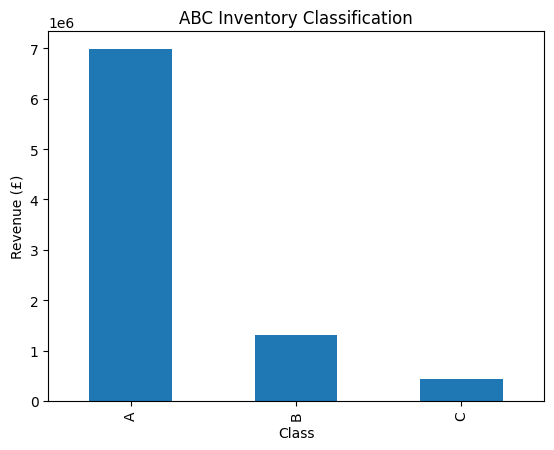

In [226]:
class_rev = abc.groupby('Class')['Revenue'].sum()

class_rev.plot(kind='bar')

plt.title('ABC Inventory Classification')
plt.ylabel('Revenue (£)')
plt.show()

### ABC Inventory Classification

- ABC result: Revenue is concentrated in Class A.
- Top SKU result: Revenue is still diversified within Class A.
 

*ABC analysis shows that Class A products generated approximately £8.0 million in revenue, accounting for 80% of total revenue. Although Class A products represent only 21.3% of all SKUs (783 out of 3,660), they contribute the majority of sales.*
 

*In contrast, Class B and Class C products contributed approximately 15% and 5% of total revenue, respectively. This indicates that revenue is highly concentrated in Class A products, making them the highest-priority items for inventory management and demand forecasting.*

 
*Although Class A products generate approximately 80% of total revenue, revenue is not concentrated in a small number of individual products. The top 10 revenue-generating SKUs in Class A account for only 9.7% of total revenue. This suggests that sales are distributed across many Class A items rather than being dependent on a few dominant products.*

In [227]:
abc.to_csv('abc_table.csv', index=False)

In [228]:
data.to_csv('cleaned_online_retail.csv')